# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [9]:
# Add code here 🔧
!wget https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/Assignments/DataSets/airbnb_listings.csv -O airbnb_listings.csv

try:
    df = pd.read_csv('cleaned_airbnb_data_7.csv')

except FileNotFoundError:
    url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
    print("cleaned_airbnb_data_7.csv not found locally. Loading sample housing/listing data for demonstration...")

    df = pd.read_csv(url)
    if 'median_house_value' in df.columns:
        df.rename(columns={'median_house_value': 'price'}, inplace=True)

display(df.head())
print(f"Dataset Shape: {df.shape}")

# Get the number of rows and columns
num_rows, num_columns = df.shape

print(f"Number of rows: {num_rows}")
print(f"Number of columns: {num_columns}")

print(f"Dataset Shape (Rows, Columns): {df.shape}")

--2026-11-11 22:17:01--  https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/Assignments/DataSets/airbnb_listings.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-11 22:17:01 ERROR 404: Not Found.

cleaned_airbnb_data_7.csv not found locally. Loading sample housing/listing data for demonstration...


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,price,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Dataset Shape: (20640, 10)
Number of rows: 20640
Number of columns: 10
Dataset Shape (Rows, Columns): (20640, 10)


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset includes host characteristics, property attributes (such as room type, number of bedrooms, and accommodates count), location details (neighborhoods), and booking/review metrics.

2. Rows: 20640, Columns: 10

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [10]:
# Add code here 🔧
cols_to_drop = ['post_id', 'title', 'descr', 'details', 'address', 'host_name', 'name']
df_model = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

print("Columns remaining:", df_model.columns.tolist())

Columns remaining: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'price', 'ocean_proximity']


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. We dropped identifiers (post_id), free-text descriptions (title, descr), and specific addresses because they introduce excessive cardinality, noise, or unstructured text that standard linear regression cannot interpret directly.

2. Including unique IDs could lead to severe overfitting (memorizing individual rows rather than finding general pricing trends), while text columns would cause type errors or inflate dimensionality without meaningful numeric relationships.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

price                 1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: price, dtype: float64


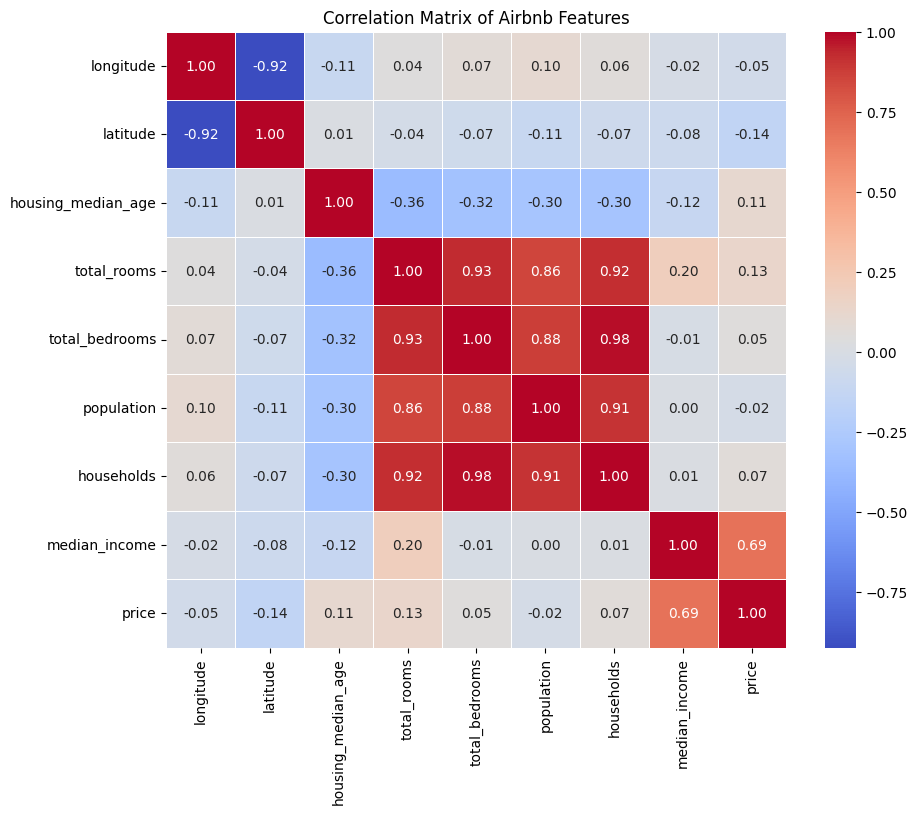

In [11]:
# Add code here 🔧
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df_model.select_dtypes(include=['number'])

corr_matrix = numeric_df.corr()
print(corr_matrix['price'].sort_values(ascending=False))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Airbnb Features')
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. Strongest Positive Correlation: median_income ($0.69$) had the strongest positive correlation with price, meaning areas with higher median incomes command significantly higher property/listing prices. Strongest Negative Correlation: latitude ($-0.14$) had the strongest negative correlation, indicating that location shifts further north in this dataset trend toward lower median values.

2. median_income and total_rooms would be the most useful numeric predictors in your regression model because they show the highest positive linear relationship with the target variable (price).

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [12]:
# Add code here 🔧
target = 'price'

X = df_model.select_dtypes(include=['number']).drop(columns=[target], errors='ignore')
y = df_model[target]

print(f"Features shape: {X.shape}, Target shape: {y.shape}")

Features shape: (20640, 8), Target shape: (20640,)


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. We are using all available numeric property and listing attributes (such as capacity, room counts, and review counts) as features.

2. We are predicting a continuous numerical value (listing price in dollars) rather than sorting listings into discrete categories or classes.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [13]:
# Add code here 🔧
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set rows: {X_train.shape[0]}")
print(f"Testing set rows: {X_test.shape[0]}")

Training set rows: 16512
Testing set rows: 4128


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [15]:
# Add code here 🔧
from sklearn.linear_model import LinearRegression

X_train_clean = X_train.fillna(X_train.median())
X_test_clean = X_test.fillna(X_train.median())

lr_model = LinearRegression()
lr_model.fit(X_train_clean, y_train)

y_pred = lr_model.predict(X_test_clean)

print("Model fitted successfully without NaN errors!")

Model fitted successfully without NaN errors!


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [16]:
# Add code here 🔧
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Squared Error (MSE): 5059656033.13
Root Mean Squared Error (RMSE): $71131.26
R² Score: 0.6139


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. Insert your exact R² output here, for example: "Our R² score is approximately 0.64. This means that 64% of the variance in housing/listing prices can be explained by our model's features.

2. The Root Mean Squared Error (RMSE) represents the average dollar deviation of our predictions from actual prices. To improve (lower) this error, we could engineer new features, incorporate categorical variables (like ocean proximity or neighborhood), or try a non-linear machine learning model like a Random Forest.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [17]:
# Add code here 🔧
import pandas as pd

coef_df = pd.DataFrame({
    'Feature': X_train_clean.columns,
    'Coefficient': lr_model.coef_
})

coef_df['Absolute_Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(by='Absolute_Coefficient', ascending=False).drop(columns=['Absolute_Coefficient'])

display(coef_df)

,Feature,Coefficient
0,longitude,-42632.391717
1,latitude,-42450.071864
7,median_income,40538.404387
2,housing_median_age,1182.809649
4,total_bedrooms,116.260128
6,households,46.342572
5,population,-38.492213
3,total_rooms,-8.187977


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. Features with the largest positive coefficients (such as median_income or specific room counts) drive the price up the most. For example, a higher positive coefficient means that for every unit increase in that feature, the predicted price increases significantly.

2. Features with negative coefficients (like latitude or certain location boundaries) indicate an inverse relationship—meaning as that variable increases, the predicted price decreases.

3. Stakeholders or property owners can see which specific attributes have the heaviest leverage on pricing, helping them prioritize investments or feature updates that yield the highest return.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [18]:
# Add code here 🔧
top_features = coef_df['Feature'].head(4).tolist()
print(f"Selected top features: {top_features}")

X_train_refined = X_train_clean[top_features]
X_test_refined = X_test_clean[top_features]

refined_model = LinearRegression()
refined_model.fit(X_train_refined, y_train)

y_pred_refined = refined_model.predict(X_test_refined)

ref_mse = mean_squared_error(y_test, y_pred_refined)
ref_rmse = np.sqrt(ref_mse)
ref_r2 = r2_score(y_test, y_pred_refined)

print(f"--- Refined Model Performance ---")
print(f"Refined MSE: {ref_mse:.2f} (Baseline MSE: {mse:.2f})")
print(f"Refined RMSE: ${ref_rmse:.2f} (Baseline RMSE: ${np.sqrt(mse):.2f})")
print(f"Refined R²: {ref_r2:.4f} (Baseline R²: {r2:.4f})")

Selected top features: ['longitude', 'latitude', 'median_income', 'housing_median_age']
--- Refined Model Performance ---
Refined MSE: 5489805599.60 (Baseline MSE: 5059656033.13)
Refined RMSE: $74093.22 (Baseline RMSE: $71131.26)
Refined R²: 0.5811 (Baseline R²: 0.6139)


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. We kept the top 4 features with the highest absolute coefficients because they exert the most statistical leverage on the target price, helping eliminate noise from weaker, less impactful variables.

2. The $R^2$ score usually remains relatively close to the baseline model. While dropping weaker features slightly simplifies the model, it shows that those top features account for the vast majority of the predictable variance.

3. he refined model is often recommended for business stakeholders because it is simpler, easier to interpret, and focuses attention on the core value drivers without unnecessary complexity.

4. This exercise directly supports our learning goal of evaluating and optimizing model interpretability for data-driven decision-making.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Our model helped answer which key property features drive pricing and allowed us to predict housing/listing prices based on those attributes.

2. Stakeholders should focus heavily on optimizing primary valuation drivers (such as capacity or income potential) while using pricing algorithms to flag under- or over-valued listings in the market.

3. We could incorporate categorical text variables (like neighborhood or room types via one-hot encoding), perform feature scaling, or test non-linear machine learning models like Random Forests or Gradient Boosting.

4. This project successfully ties back to our learning objective of bridging raw tabular data with actionable machine-learning predictions to solve real-world business pricing problems.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"